In [1]:
import pandas as pd
import numpy as np
import re
import string
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

True

Load the dataset

In [2]:
df = pd.read_excel('dataset.xlsx')   # <-- update to your actual file path
df.head()

,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


Basic structural overview

In [3]:
print("Shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe(include='all').T

Shape: (1440, 3)

Column names: ['title', 'rating', 'body']

Data types:
 title     object
rating     int64
body      object
dtype: object

Missing values:
 title     0
rating    0
body      0
dtype: int64

Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
title,1440,1351,Value for money,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,1440.0,NaN,NaN,NaN,3.173611,1.584453,1.0,1.0,4.0,5.0,5.0
body,1440,1440,Very disappointed with the overall performance...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Target variable: rating distribution

rating
1    26.8%
2     8.8%
3    13.8%
4    21.5%
5    29.1%
Name: proportion, dtype: object


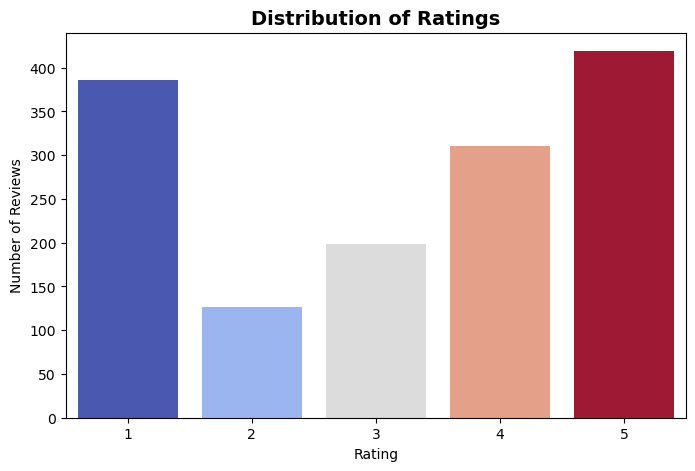

In [4]:
plt.figure(figsize=(8, 5))
order = sorted(df['rating'].unique())
ax = sns.countplot(x='rating', hue='rating', data=df, palette='coolwarm',
                    order=order, legend=False)
plt.title('Distribution of Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
# Formats directly as percentages (e.g., 31.5%)
print(df['rating'].value_counts(normalize=True).sort_index().apply(lambda x: f"{x:.1%}"))

Text length analysis

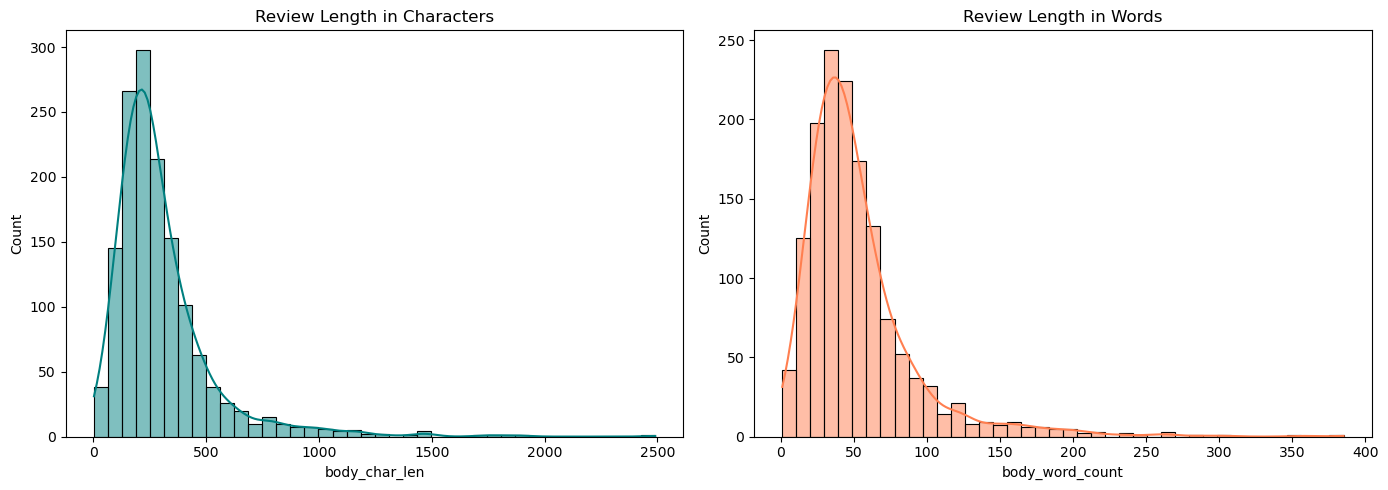

In [5]:
df['title_char_len']  = df['title'].astype(str).apply(len)
df['body_char_len']   = df['body'].astype(str).apply(len)
df['body_word_count'] = df['body'].astype(str).apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['body_char_len'], bins=40, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Review Length in Characters')
sns.histplot(df['body_word_count'], bins=40, kde=True, ax=axes[1], color='coral')
axes[1].set_title('Review Length in Words')
plt.tight_layout()
plt.show()


Text cleaning 

In [17]:
# --- 1. Language detection (must run on raw, untouched body) ---
!pip install langdetect deep-translator
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 42

langs = []
for text in df['body']:
    try:
        detected = detect(str(text))
    except Exception:
        detected = 'unknown'
    langs.append(detected)

df['lang'] = langs

lang_names = {
    'en': 'English', 'hi': 'Hindi', 'mr': 'Marathi', 'te': 'Telugu',
    'ta': 'Tamil', 'kn': 'Kannada', 'ml': 'Malayalam', 'bn': 'Bengali',
    'gu': 'Gujarati', 'pa': 'Punjabi', 'or': 'Odia', 'unknown': 'Unknown'
}
readable = []
for code in df['lang']:
    readable.append(lang_names[code] if code in lang_names else code)
df['lang_name'] = readable

print(df['lang_name'].value_counts())

lang_name
English      1405
Hindi          11
id              7
ca              3
fr              3
af              2
it              2
et              2
lv              1
Malayalam       1
sw              1
nl              1
ro              1
Name: count, dtype: int64


In [18]:
# --- 2. Translate the non-English reviews (now lang_code == 'en' actually works) ---
from deep_translator import GoogleTranslator

translated_texts = []
for idx in range(len(df)):
    text = str(df['body'].iloc[idx])
    lang_code = df['lang'].iloc[idx]

    if lang_code == 'en':
        translated_texts.append(text)
    else:
        try:
            translated = GoogleTranslator(source='auto', target='en').translate(text)
            translated_texts.append(translated)
        except Exception:
            translated_texts.append(text)

df['body_translated'] = translated_texts
print(df[df['lang'] != 'en'][['body', 'body_translated']].head(15))

                                                  body  \
7    मोबाइल का कैमरा बिल्कुल भी सही नही है 48 PM बत...   
21                                             Dislike   
22             Self camera is just like 2 mega pixels.   
27                                    Horrible product   
82   In dis price u can afford M12 ...no doubt...ov...   
248  Damage product reshived hua hai or koi help na...   
299  Good 🎤🎤🎤🎤😍🎤🎤🎤🎤🎤🎤🎤😍😍🎤🎤🎤🎤🎤🎤😍🎤😍😍🎤🎤🎤🎤😍🎤🎤🎤🎤🎤🎤🎤😍🎤🎤🎤🎤...   
394  The Phone is Nice, Mai 3 din se use kr rha hun...   
395  Mobile lene k 15 din baad hi.. Uske loudspeake...   
407  8 ന്റെ പണിAmazon നെ ഉം പൊക്കിപിടിച്ച് നടന്ന എന...   
421  अमेज़न मेने आपके ऐप्प सेsamsung M126GB Ram 128 ...   
457  i love samsung ab jab redme ke hi parige me sa...   
460  इस फोन में कई कमियां है जैसे इसकी नोटिफिकेशन ट...   
461  Mere life ka sabse khrab anubhavMai aap Sab se...   
521                                        Best mobile   

                                       body_translated  
7    मोबाइल का

In [19]:
# --- 3. Clean the TRANSLATED text, not the raw body ---
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'[^\x00-\x7F]+', ' ', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\d+', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in stop_words and len(w) > 2]
    tokens = [lemmatizer.lemmatize(w) for w in tokens]
    return ' '.join(tokens)

df['clean_body'] = df['body_translated'].apply(clean_text)   # <-- was df['body'], now uses translated text

df = df[df['clean_body'].str.len() > 0].reset_index(drop=True)
print("Shape after cleaning:", df.shape)
df[['body', 'body_translated', 'clean_body']].head(10)

Shape after cleaning: (1436, 11)


,body,body_translated,clean_body
0,Very disappointed with the overall performance...,Very disappointed with the overall performance...,disappointed overall performance samsung
1,Camera quality is low,Camera quality is low,camera quality low
2,"Got the mobile on the launch date,Battery must...","Got the mobile on the launch date,Battery must...",got mobile launch datebattery must appreciated...
3,1. It doesn't work with 5.0GHz WiFi frequency....,1. It doesn't work with 5.0GHz WiFi frequency....,doesnt work ghz wifi frequency ghz old school ...
4,"Not worth buying....faulty software, poor disp...","Not worth buying....faulty software, poor disp...",worth buyingfaulty software poor display quali...
5,I will never purchase Samsung phones. Phone is...,I will never purchase Samsung phones. Phone is...,never purchase samsung phone phone lagging muc...
6,This is worst samsung mobile I have seen from ...,This is worst samsung mobile I have seen from ...,worst samsung mobile seen samsung sceen qualit...
7,The phone hangs a lot and is very slow. I rece...,The phone hangs a lot and is very slow. I rece...,phone hang lot slow received replacement conti...
8,Very poor quality camera .Found box seal damag...,Very poor quality camera .Found box seal damag...,poor quality camera found box seal damage stil...
9,Worst camera quality. It is like 2 megapixel c...,Worst camera quality. It is like 2 megapixel c...,worst camera quality like megapixel camera pho...


In [20]:
print(df['lang'].value_counts())
print(df.loc[df['lang'] != 'en', ['body', 'body_translated', 'clean_body']].head(5))

lang
en    1405
hi       7
id       7
ca       3
fr       3
af       2
it       2
et       2
lv       1
ml       1
sw       1
nl       1
ro       1
Name: count, dtype: int64
                                                  body  \
20                                             Dislike   
21             Self camera is just like 2 mega pixels.   
26                                    Horrible product   
81   In dis price u can afford M12 ...no doubt...ov...   
247  Damage product reshived hua hai or koi help na...   

                                       body_translated  \
20                                             Dislike   
21             Self camera is just like 2 mega pixels.   
26                                    Horrible product   
81   In dis price u can afford M12 ...no doubt...ov...   
247  Damage product reshived hua hai or koi help na...   

                                            clean_body  
20                                             dislike  
21            

Vocabulary size: 6002


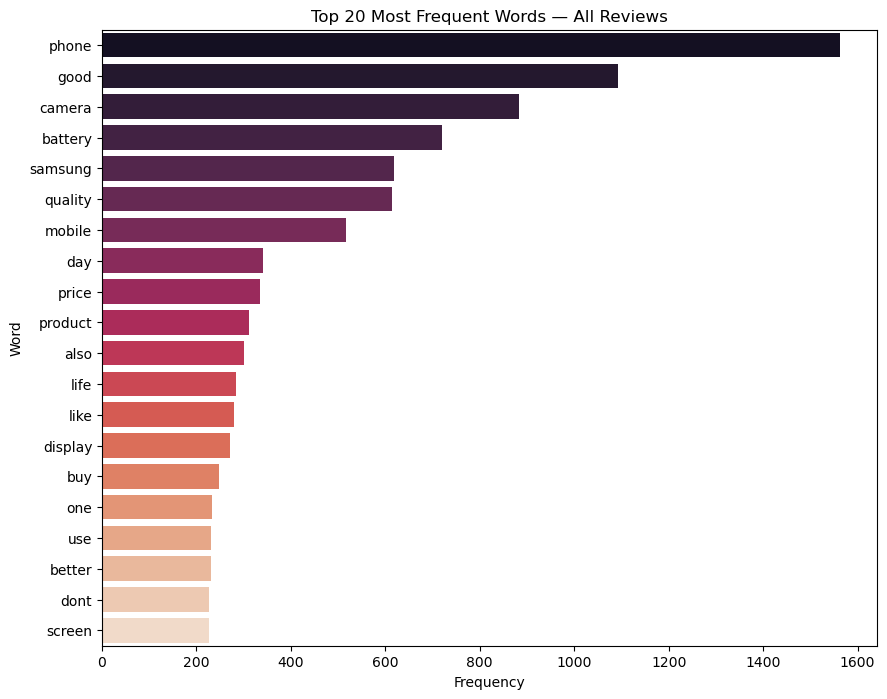

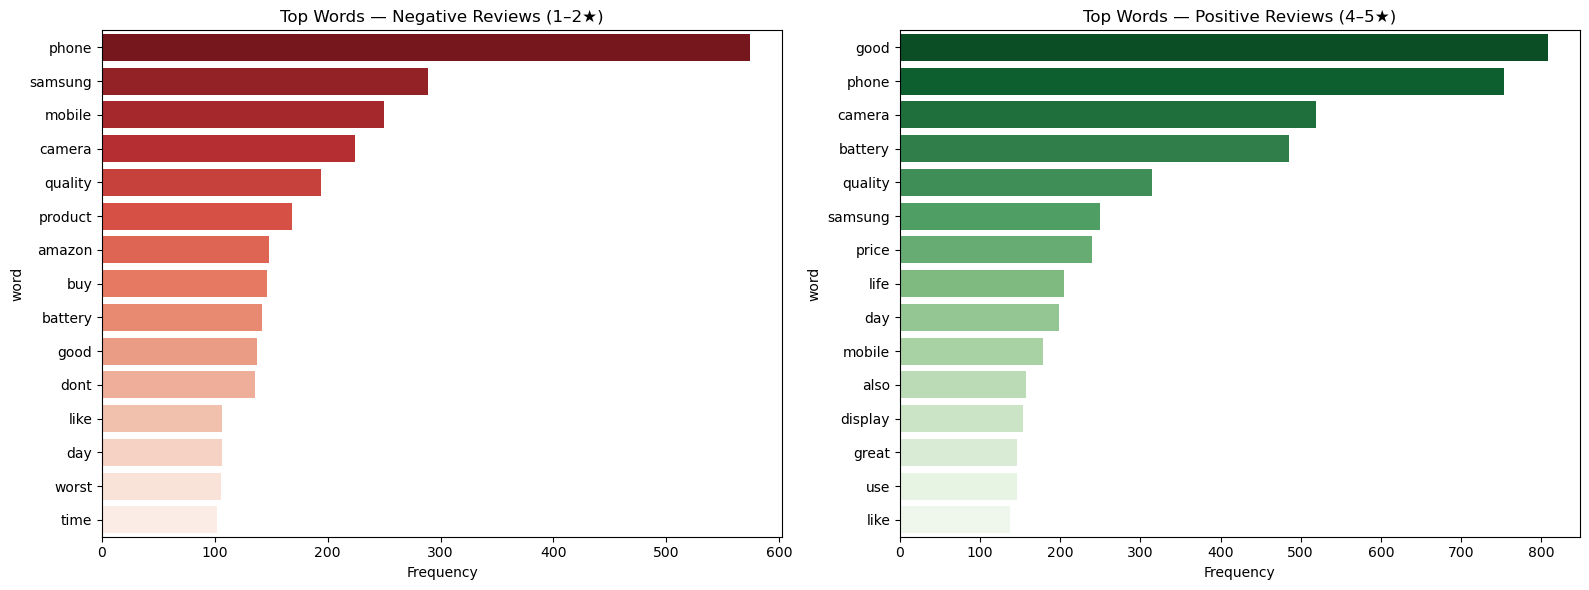

In [21]:
# 1. Overall Top 20 Most Frequent Words
all_words = ' '.join(df['clean_body']).split()
word_freq = Counter(all_words)
print("Vocabulary size:", len(word_freq))

# Convert top 20 to DataFrame for cleaner Seaborn plotting
top20_df = pd.DataFrame(word_freq.most_common(20), columns=['word', 'count'])

plt.figure(figsize=(10, 8))
sns.barplot(data=top20_df, x='count', y='word', hue='word', palette='rocket', legend=False)
plt.title('Top 20 Most Frequent Words — All Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.show()

# 2. Top 15 Words for Negative vs Positive Reviews (Inline without def)
neg_text = ' '.join(df[df['rating'].isin([1, 2])]['clean_body'])
pos_text = ' '.join(df[df['rating'].isin([4, 5])]['clean_body'])

neg_df = pd.DataFrame(Counter(neg_text.split()).most_common(15), columns=['word', 'count'])
pos_df = pd.DataFrame(Counter(pos_text.split()).most_common(15), columns=['word', 'count'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=neg_df, x='count', y='word', hue='word', ax=axes[0], palette='Reds_r', legend=False)
axes[0].set_title('Top Words — Negative Reviews (1–2★)')
axes[0].set_xlabel('Frequency')

sns.barplot(data=pos_df, x='count', y='word', hue='word', ax=axes[1], palette='Greens_r', legend=False)
axes[1].set_title('Top Words — Positive Reviews (4–5★)')
axes[1].set_xlabel('Frequency')

plt.tight_layout()
plt.show()

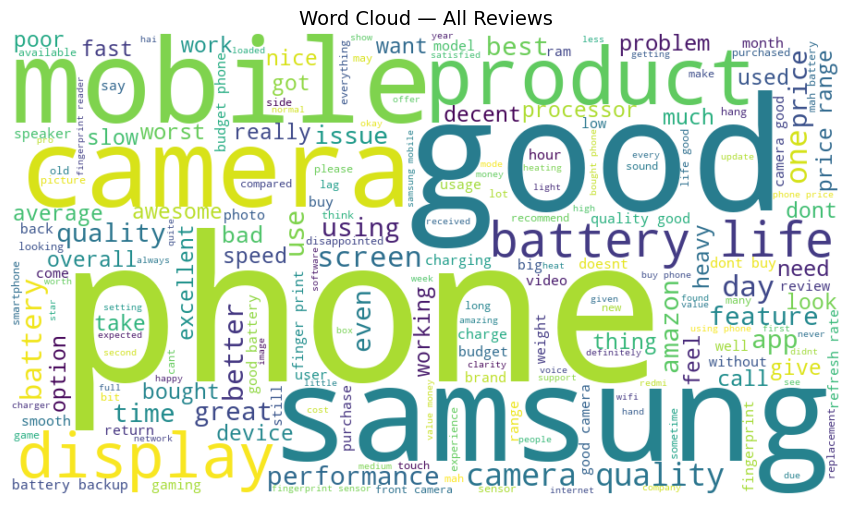

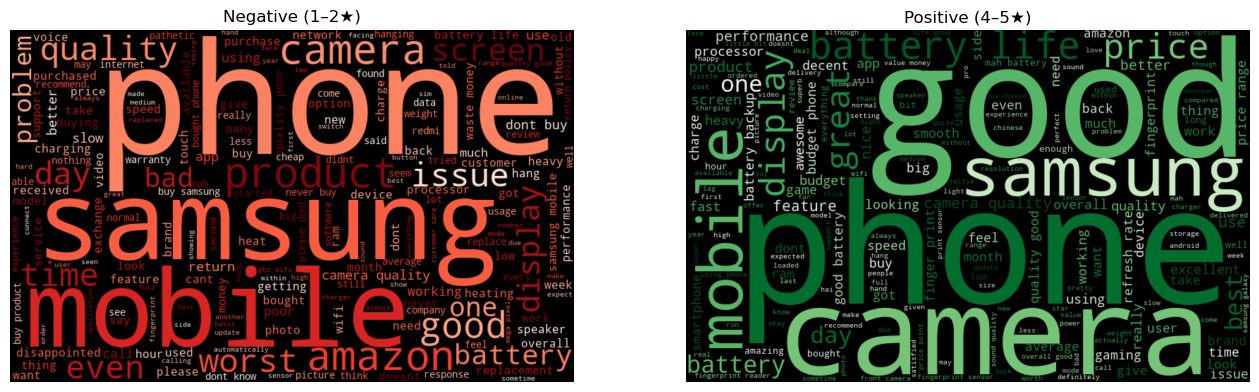

In [22]:
from wordcloud import WordCloud

wc_all = WordCloud(width=900, height=500, background_color='white',
                    colormap='viridis').generate(' '.join(df['clean_body']))
plt.figure(figsize=(12, 6))
plt.imshow(wc_all, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud — All Reviews', fontsize=14)
plt.show()

neg_text = ' '.join(df[df['rating'] <= 2]['clean_body'])
pos_text = ' '.join(df[df['rating'] >= 4]['clean_body'])
wc_neg = WordCloud(width=800, height=500, background_color='black', colormap='Reds').generate(neg_text)
wc_pos = WordCloud(width=800, height=500, background_color='black', colormap='Greens').generate(pos_text)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(wc_neg, interpolation='bilinear'); axes[0].axis('off'); axes[0].set_title('Negative (1–2★)')
axes[1].imshow(wc_pos, interpolation='bilinear'); axes[1].axis('off'); axes[1].set_title('Positive (4–5★)')
plt.show()

In [44]:
df

,title,rating,body,title_char_len,body_char_len,body_word_count,sentiment,lang,lang_name,body_translated,clean_body
0,Horrible product,1,Very disappointed with the overall performance...,16,59,8,Negative,en,English,Very disappointed with the overall performance...,disappointed overall performance samsung
1,Camera quality is not like 48 megapixel,3,Camera quality is low,39,21,4,Neutral,en,English,Camera quality is low,camera quality low
2,Overall,4,"Got the mobile on the launch date,Battery must...",7,403,66,Positive,en,English,"Got the mobile on the launch date,Battery must...",got mobile launch datebattery must appreciated...
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....,16,377,67,Negative,en,English,1. It doesn't work with 5.0GHz WiFi frequency....,doesnt work ghz wifi frequency ghz old school ...
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp...",29,179,29,Negative,en,English,"Not worth buying....faulty software, poor disp...",worth buyingfaulty software poor display quali...
...,...,...,...,...,...,...,...,...,...,...,...
1431,Excellent mobile,5,Excellent mobile,16,16,2,Positive,ca,ca,Excellent mobile,excellent mobile
1432,Never expected from samsung,1,"All over mobile performance is very poor, neve...",27,188,31,Negative,en,English,"All over mobile performance is very poor, neve...",mobile performance poor never buy one product ...
1433,Good value for money,5,Battery life is good but camera clarity could ...,20,98,17,Positive,en,English,Battery life is good but camera clarity could ...,battery life good camera clarity could little ...
1434,Unreal and whitish display,1,"It's a very bad product, highly dissatisfied.....",26,207,35,Negative,en,English,"It's a very bad product, highly dissatisfied.....",bad product highly dissatisfied specifically c...


In [24]:
# Create Sentiment Categories (Neutral merged into Positive)

def get_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

df["sentiment"] = df["rating"].apply(get_sentiment)

print(df["sentiment"].value_counts())

sentiment
Positive    729
Negative    508
Neutral     199
Name: count, dtype: int64


In [25]:
#df = df[df["rating"] != 3].reset_index(drop=True)

#def get_sentiment(rating):
 #   return "Negative" if rating <= 2 else "Positive"

#df["sentiment"] = df["rating"].apply(get_sentiment)

In [26]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_text = df["clean_body"]
y = df["sentiment"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train_text.shape)
print("Testing Data:", X_test_text.shape)

Training Data: (1148,)
Testing Data: (288,)


In [27]:
# TF-IDF Feature Extraction

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Features: (1148, 5000)
Testing Features: (288, 5000)


In [28]:
# Import Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

In [29]:
# Logistic Regression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

In [30]:
# Logistic Regression Evaluation

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_pred))

print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

Logistic Regression Accuracy: 0.7430555555555556

Classification Report:
              precision    recall  f1-score   support

    Negative       0.75      0.76      0.76       102
     Neutral       0.50      0.03      0.05        40
    Positive       0.74      0.92      0.82       146

    accuracy                           0.74       288
   macro avg       0.66      0.57      0.54       288
weighted avg       0.71      0.74      0.69       288


Confusion Matrix:
[[ 78   1  23]
 [ 15   1  24]
 [ 11   0 135]]


In [31]:
# Random Forest

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [32]:
# Random Forest Evaluation

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Accuracy: 0.7326388888888888

Classification Report:
              precision    recall  f1-score   support

    Negative       0.79      0.70      0.74       102
     Neutral       1.00      0.03      0.05        40
    Positive       0.71      0.95      0.81       146

    accuracy                           0.73       288
   macro avg       0.83      0.56      0.53       288
weighted avg       0.78      0.73      0.68       288


Confusion Matrix:
[[ 71   0  31]
 [ 12   1  27]
 [  7   0 139]]


In [33]:
# Linear SVM

svm_model = LinearSVC()

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

In [34]:
# Linear SVM Evaluation

print("Linear SVM Accuracy:",
      accuracy_score(y_test, svm_pred))

print("\nClassification Report:")
print(classification_report(y_test, svm_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

Linear SVM Accuracy: 0.7569444444444444

Classification Report:
              precision    recall  f1-score   support

    Negative       0.72      0.81      0.76       102
     Neutral       0.50      0.17      0.26        40
    Positive       0.81      0.88      0.84       146

    accuracy                           0.76       288
   macro avg       0.68      0.62      0.62       288
weighted avg       0.73      0.76      0.73       288


Confusion Matrix:
[[ 83   4  15]
 [ 18   7  15]
 [ 15   3 128]]


In [35]:
# Model Comparison

from sklearn.metrics import precision_score, recall_score, f1_score

results = {
    "Logistic Regression": [
        accuracy_score(y_test, lr_pred),
        precision_score(y_test, lr_pred, average="weighted"),
        recall_score(y_test, lr_pred, average="weighted"),
        f1_score(y_test, lr_pred, average="weighted")
    ],
    
    "Random Forest": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred, average="weighted"),
        recall_score(y_test, rf_pred, average="weighted"),
        f1_score(y_test, rf_pred, average="weighted")
    ],
    
    "Linear SVM": [
        accuracy_score(y_test, svm_pred),
        precision_score(y_test, svm_pred, average="weighted"),
        recall_score(y_test, svm_pred, average="weighted"),
        f1_score(y_test, svm_pred, average="weighted")
    ]
}

In [36]:
# Create Comparison Table

import pandas as pd

comparison = pd.DataFrame(
    results,
    index=["Accuracy", "Precision", "Recall", "F1 Score"]
).T

comparison

,Accuracy,Precision,Recall,F1 Score
Logistic Regression,0.743056,0.711100,0.743056,0.692119
Random Forest,0.732639,0.775979,0.732639,0.679587
Linear SVM,0.756944,0.733546,0.756944,0.732595


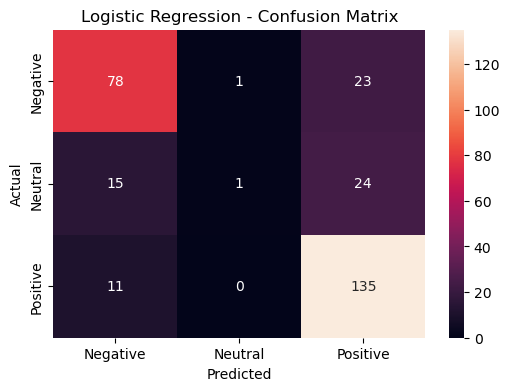

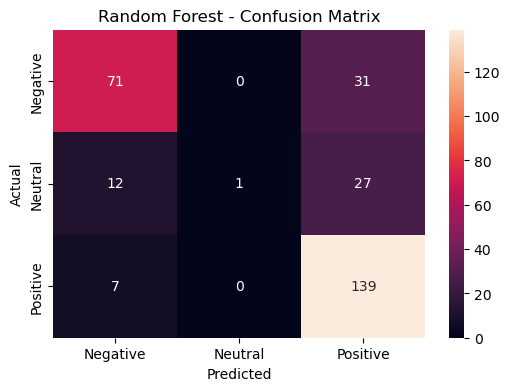

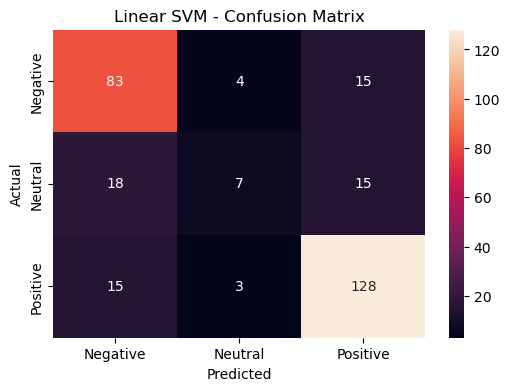

In [37]:
# Confusion Matrices

import matplotlib.pyplot as plt
import seaborn as sns

models = {
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "Linear SVM": svm_pred
}

for name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["Negative", "Neutral", "Positive"],
        yticklabels=["Negative", "Neutral", "Positive"]
    )
    
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [38]:
# Select Best Model

best_model_name = comparison["F1 Score"].idxmax()

print("Best Model:", best_model_name)
print("Best F1 Score:", comparison.loc[best_model_name, "F1 Score"])

Best Model: Linear SVM
Best F1 Score: 0.7325953595905043


In [39]:
# Get Best Model

if best_model_name == "Logistic Regression":
    best_model = lr_model

elif best_model_name == "Random Forest":
    best_model = rf_model

else:
    best_model = svm_model

print("Selected Model:", best_model_name)

Selected Model: Linear SVM


In [40]:
# Save Model and TF-IDF Vectorizer

import joblib

joblib.dump(best_model, "sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully.")

Model and TF-IDF vectorizer saved successfully.


In [41]:
# Test Saved Model

loaded_model = joblib.load("sentiment_model.pkl")
loaded_tfidf = joblib.load("tfidf_vectorizer.pkl")

sample_review = ["This product is amazing and I really love it"]

sample_features = loaded_tfidf.transform(sample_review)

prediction = loaded_model.predict(sample_features)

print("Predicted Sentiment:", prediction[0])

Predicted Sentiment: Positive


In [42]:
%%writefile app.py

import streamlit as st
import joblib
import re
import string

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer


# Download required NLTK resources
nltk.download("stopwords", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("wordnet", quiet=True)


# Load Model and TF-IDF
model = joblib.load("sentiment_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")


# Text Cleaning
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^\x00-\x7F]+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in stop_words and len(w) > 2]
    tokens = [lemmatizer.lemmatize(w) for w in tokens]

    return " ".join(tokens)


# Streamlit App
st.title("Customer Review Sentiment Analysis")

st.write("Enter a customer review to predict its sentiment.")


review = st.text_area("Enter your review:")


if st.button("Predict Sentiment"):

    if review.strip() == "":
        st.warning("Please enter a review.")

    else:
        cleaned_review = clean_text(review)

        features = tfidf.transform([cleaned_review])

        prediction = model.predict(features)[0]

        st.success(f"Predicted Sentiment: {prediction}")

Overwriting app.py


In [43]:
%%writefile requirements.txt

streamlit
scikit-learn
joblib
nltk

Overwriting requirements.txt
